In [ ]:
import marimo as mo, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
path_to_data = mo.notebook_dir().parent / "data" / "raw" / "mpos24.csv"

In [ ]:
import urllib.request
from pathlib import Path

url = "https://data.cms.gov/sites/default/files/2026-05/b5ebab5a-f490-418a-9bce-4b9f31419356/PHY_R26_P05_V10_D24_Prov_Svc.csv" # pulled from data.cms.gov/data.json 
path_to_data.parent.mkdir(parents=True, exist_ok=True)

if not path_to_data.exists():
   urllib.request.urlretrieve(url, path_to_data)

Goal: Preprocess and visualize data, with features that make the dataset most workable for IsolationForest.

['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']


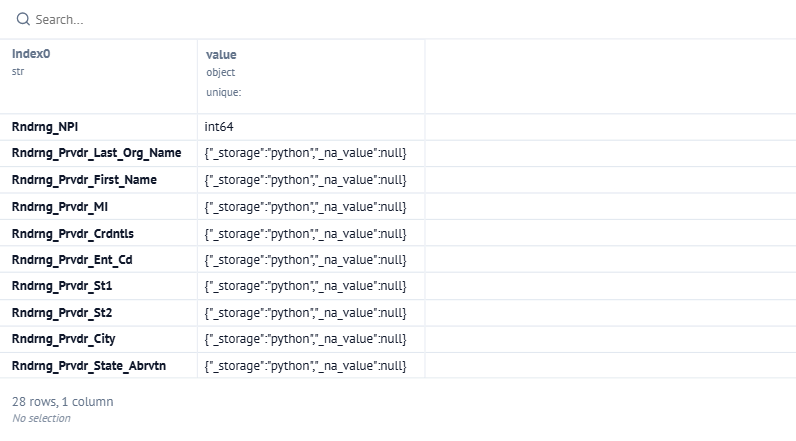

In [ ]:
sample = pd.read_csv(path_to_data, nrows=1000) # confirm variables
print(sample.columns.tolist())
sample.dtypes # must check data types to know what to fix/downcast

In [ ]:
# usecols = ['Rndrng_NPI','Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc', 'HCPCS_Drug_Ind',  'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt',  'Avg_Mdcr_Stdzd_Amt'] # columns selected for use throughout, changed 
# columns grouped for powerBI layout and lower memory useage
num_cols = {"Tot_Benes": "int32", "Tot_Srvcs": "float32", "Tot_Bene_Day_Srvcs": "int32", 
            "Avg_Sbmtd_Chrg": "float32", "Avg_Mdcr_Alowd_Amt": "float32", 
            "Avg_Mdcr_Pymt_Amt": "float32", "Avg_Mdcr_Stdzd_Amt": "float32"}
cat_cols = ["Rndrng_Prvdr_Type", "Rndrng_Prvdr_State_Abrvtn", "Rndrng_Prvdr_Ent_Cd",
            "Rndrng_Prvdr_Mdcr_Prtcptg_Ind", "Rndrng_Prvdr_Crdntls",
            "HCPCS_Cd", "HCPCS_Drug_Ind", "Place_Of_Srvc"]
fact_cols = ["Rndrng_NPI", "HCPCS_Cd", "Place_Of_Srvc", "Rndrng_Prvdr_Type",
             "Rndrng_Prvdr_State_Abrvtn", "Rndrng_Prvdr_Ent_Cd", "HCPCS_Drug_Ind", *num_cols]
prov_cols = ["Rndrng_NPI", "Rndrng_Prvdr_Last_Org_Name", "Rndrng_Prvdr_First_Name",
             "Rndrng_Prvdr_Crdntls", "Rndrng_Prvdr_City", "Rndrng_Prvdr_State_Abrvtn",
             "Rndrng_Prvdr_Type", "Rndrng_Prvdr_Ent_Cd", "Rndrng_Prvdr_Mdcr_Prtcptg_Ind"]
hcpcs_cols = ["HCPCS_Cd", "HCPCS_Desc", "HCPCS_Drug_Ind"]
usecols = sorted(set(fact_cols + prov_cols + hcpcs_cols))
dtypes = {**num_cols, **{c: "category" for c in cat_cols}}

In [ ]:
mpos24 = pd.read_csv(path_to_data, usecols=usecols, dtype=dtypes)
mpos24.shape # 20 features, 9781673 rows

In [ ]:
mpos24.duplicated(subset=['Rndrng_NPI','HCPCS_Cd','Place_Of_Srvc']).sum() # check: one row per provider, service (no duplicates)

np.int64(0)

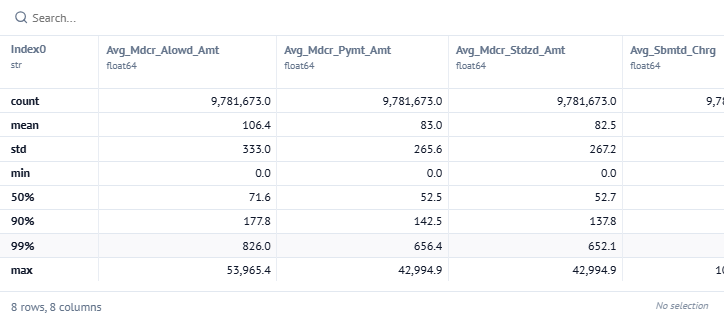

In [ ]:
print("\nmissing per column:\n", mpos24[usecols].isna().sum())
mpos24[usecols].describe(percentiles=[0.5, 0.9, 0.99]).round(1) # check skew

Feature Selection

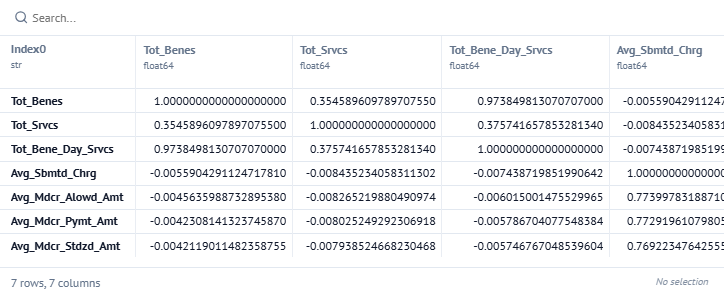

In [ ]:
mpos24[list(num_cols)].corr() # Avg_Mdcr_Alowd_Amt, Avg_Mdcr_Pymt_Amt, Avg_Mdcr_Stdzd_Amt are nigh perfectly correllated, so all three are not valuable inputs to IsoForest. Same goes for Tot_Benes and Tot_Bene_Day_Srvcs. We want to justify this visually, with the transformed variables

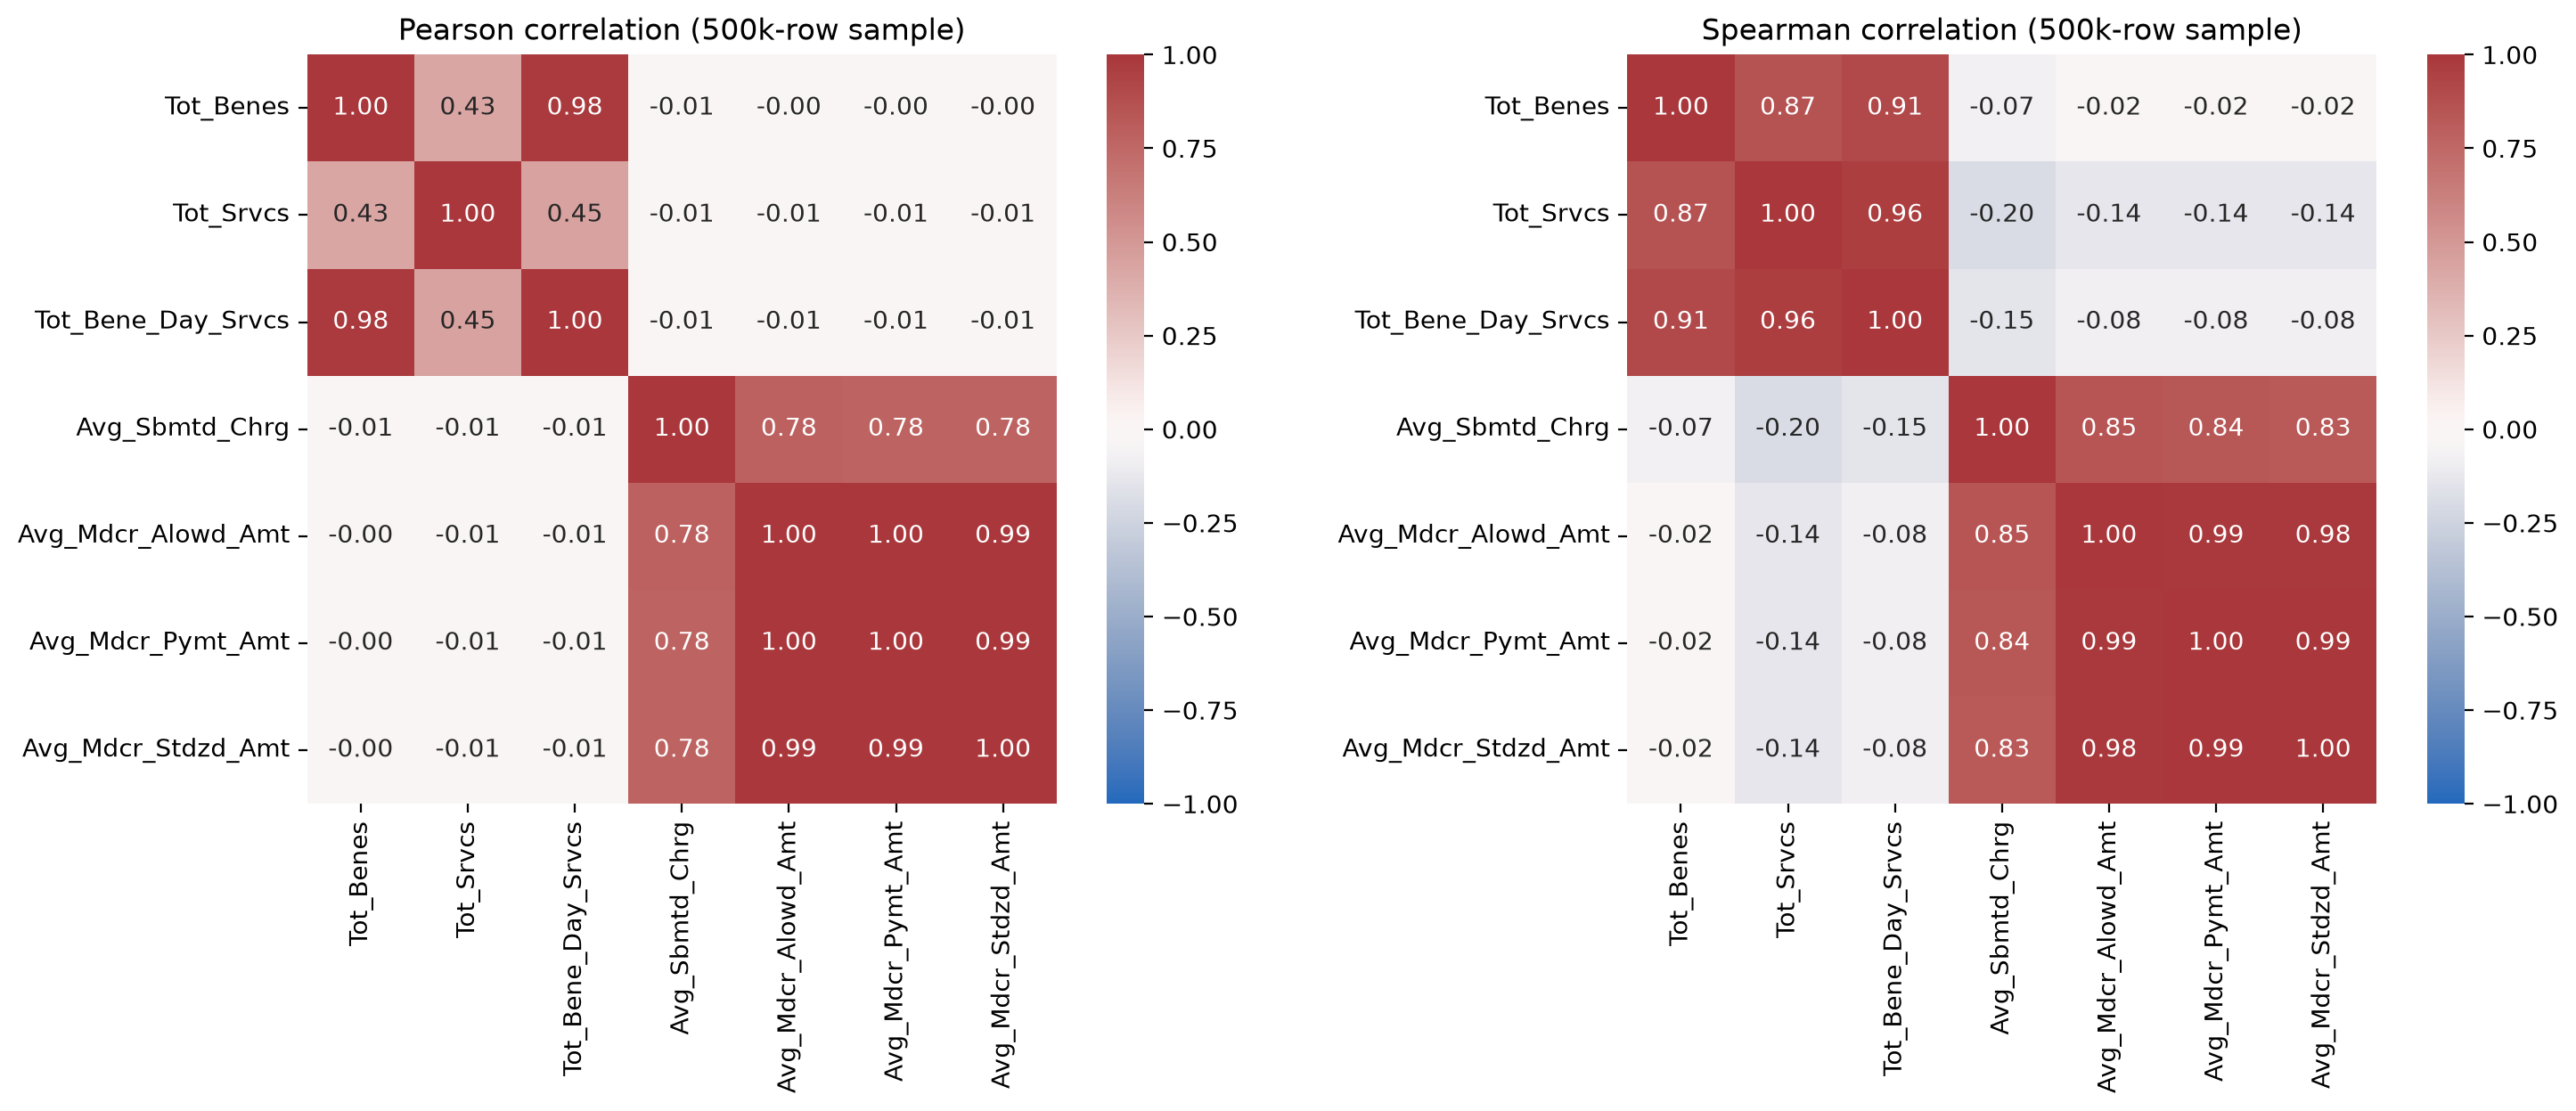

In [ ]:
_cand = ["Tot_Benes", "Tot_Srvcs", "Tot_Bene_Day_Srvcs", "Avg_Sbmtd_Chrg",
         "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Pymt_Amt", "Avg_Mdcr_Stdzd_Amt"]
_s = mpos24[_cand].sample(500_000, random_state=0)
_fig, _axes = plt.subplots(1, 2, figsize=(15, 6))
for _ax, _m in zip(_axes, ["pearson", "spearman"]):
    sns.heatmap(_s.corr(method=_m), annot=True, fmt=".2f", cmap="vlag",
                vmin=-1, vmax=1, square=True, ax=_ax)
    _ax.set_title(f"{_m.title()} correlation (500k-row sample)")
_fig.tight_layout()
_fig # initial exploration of correlation in variables
# raw pearson correlation: driven by extreme rows, but spearman, while handling skew well, will pool the rows and ignore peer groups. the latter also uses ranks when IsoForest and DBSCAN use log-scared values, so spearman will not show whether a log transformation helped. but, a log matching pearson matching spearman would be good evidence that a transformation is appropriate...... *
# raw columns and not final features mean we don't know for sure if the final features are redundant
# at a first glance, tot_srvcs - tot_benes in pearson is .43 when it's .87 in spearman

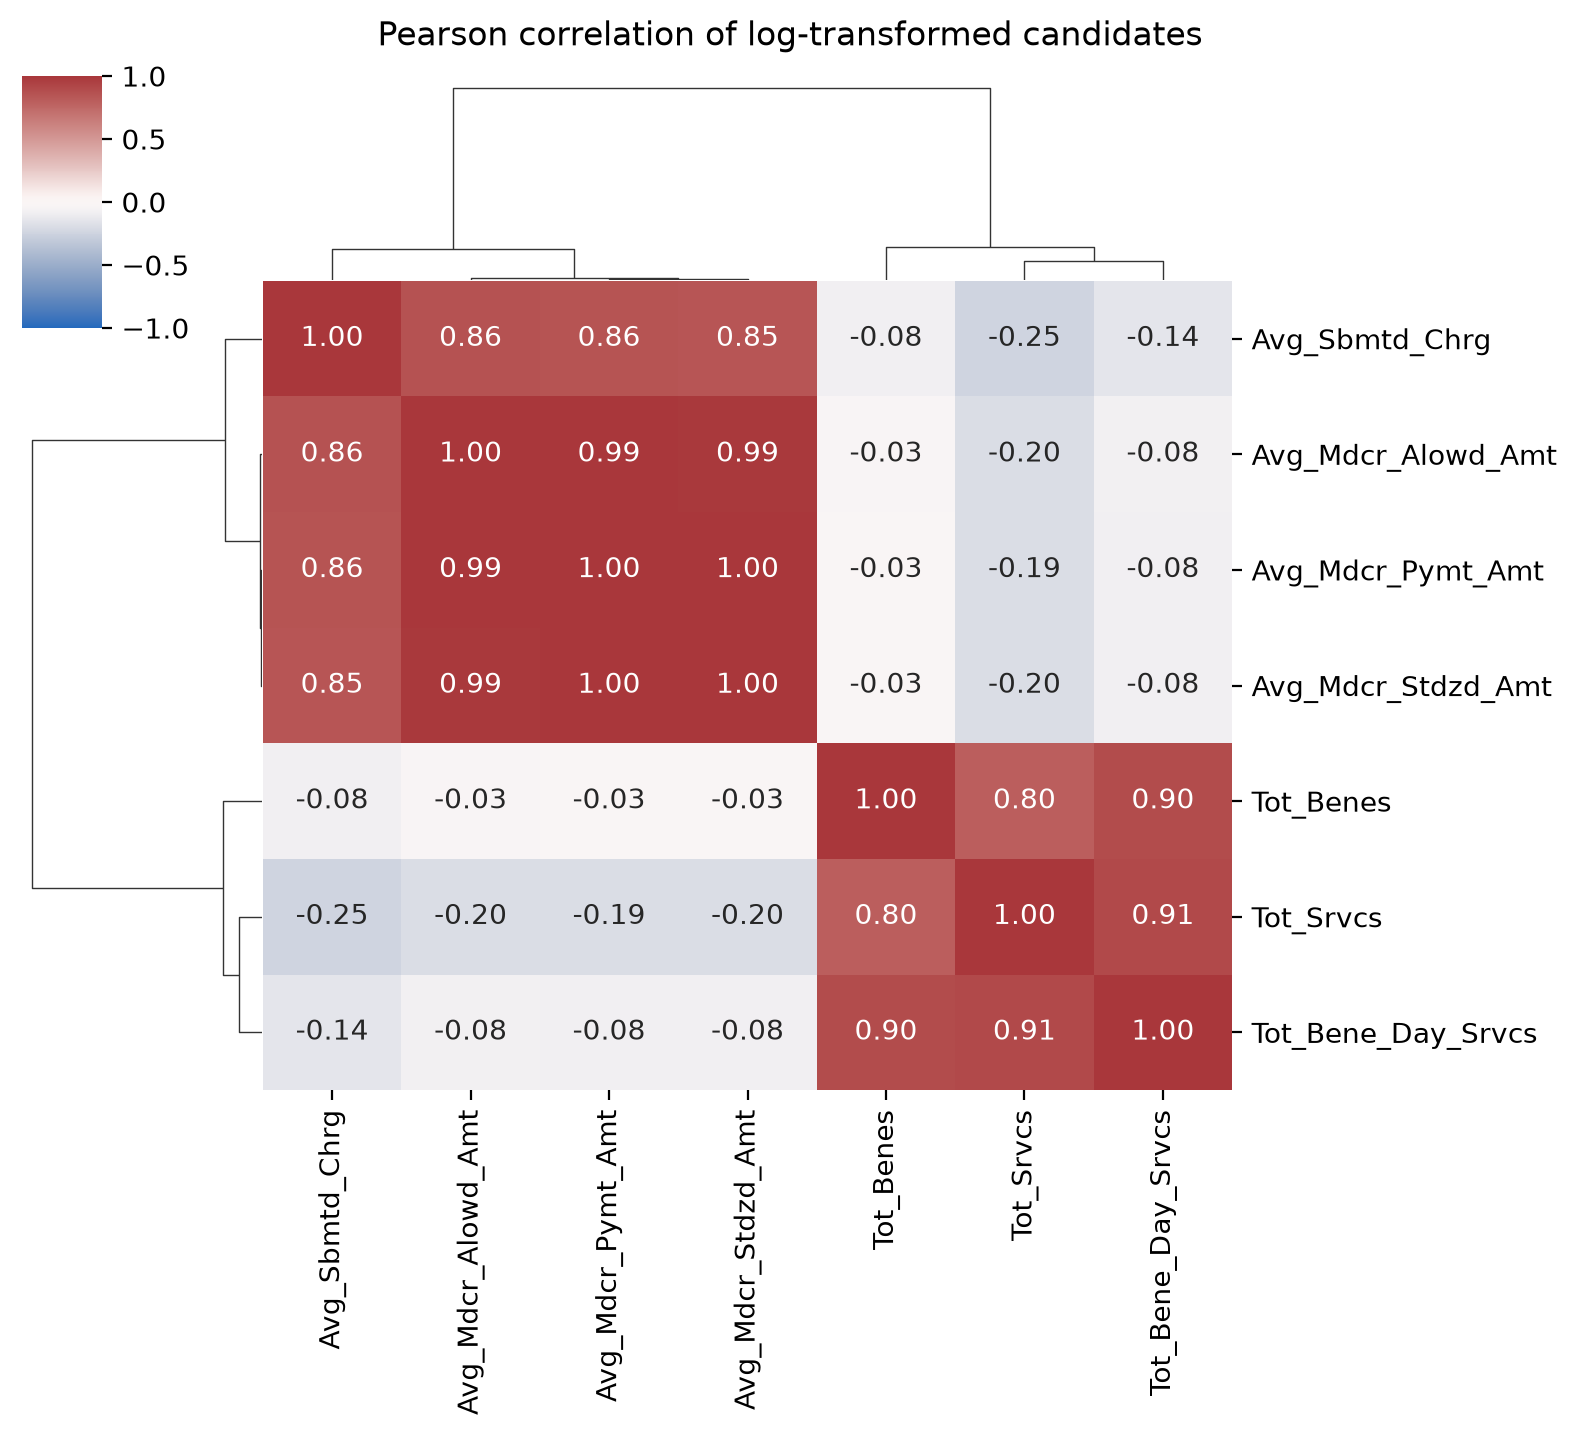

In [ ]:
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
#* ...... no way ! log pearson
_cand = ["Tot_Benes", "Tot_Srvcs", "Tot_Bene_Day_Srvcs", "Avg_Sbmtd_Chrg",
         "Avg_Mdcr_Alowd_Amt", "Avg_Mdcr_Pymt_Amt", "Avg_Mdcr_Stdzd_Amt"]
_r = np.log1p(mpos24[_cand]).corr() # defense for log transform: EXTREME skew wastes split on empty space, and z-scores assume roughly symmetric distribution
_link = linkage(squareform(1 - _r.abs(), checks=False), method="average")
_cg = sns.clustermap(_r, row_linkage=_link, col_linkage=_link, annot=True, fmt=".2f",
                     cmap="vlag", vmin=-1, vmax=1, figsize=(8, 7))
_cg.figure.suptitle("Pearson correlation of log-transformed candidates", y=1.02)
_cg.figure
# clustered so redundant groups are visible. There are two clear blocks, with less than seven "actually independendent" signals...
# this transformation aligns better with tot_srvcs - tot_benes being 0.8. Log transform pearson in agreeance with spearman means we are now describing typical rows and not outliers. 

Feature Engineering

In [ ]:
_alowd = mpos24["Avg_Mdcr_Alowd_Amt"].where(mpos24["Avg_Mdcr_Alowd_Amt"] > 0)
_chrg = mpos24["Avg_Sbmtd_Chrg"].where(mpos24["Avg_Sbmtd_Chrg"] > 0)
feats = mpos24.assign(
    log_pay=np.log1p(mpos24["Avg_Mdcr_Stdzd_Amt"]),
    log_benes=np.log1p(mpos24["Tot_Benes"]),
    log_srvcs_per_bene=np.log(mpos24["Tot_Srvcs"] / mpos24["Tot_Benes"]),
    log_markup=np.log(_chrg / _alowd),
)

In [ ]:
# as concluded from above, 
final_features = ["log_pay_rz", "log_benes_rz", "log_srvcs_per_bene_rz", "log_markup_rz"]

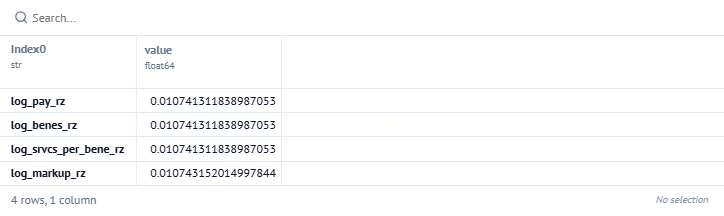

In [ ]:
_lvl1 = ["Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc"]
_lvl2 = ["HCPCS_Cd", "Place_Of_Srvc"]
_rz = {}
for _f in final_features:
    _c = _f.removesuffix("_rz")
    _rz[_f] = robust_z(feats, _c, _lvl1, 100).fillna(robust_z(feats, _c, _lvl2, 100))
peer_z = pd.DataFrame(_rz)
peer_z.isna().mean() # MAD ~ 1.07% missing for every feature, where l_p_r and l_s_p_b_r used to be ~%12 and ~%29 missing a z-score (where the typical spread is exactly 0 because the providers have identical value)

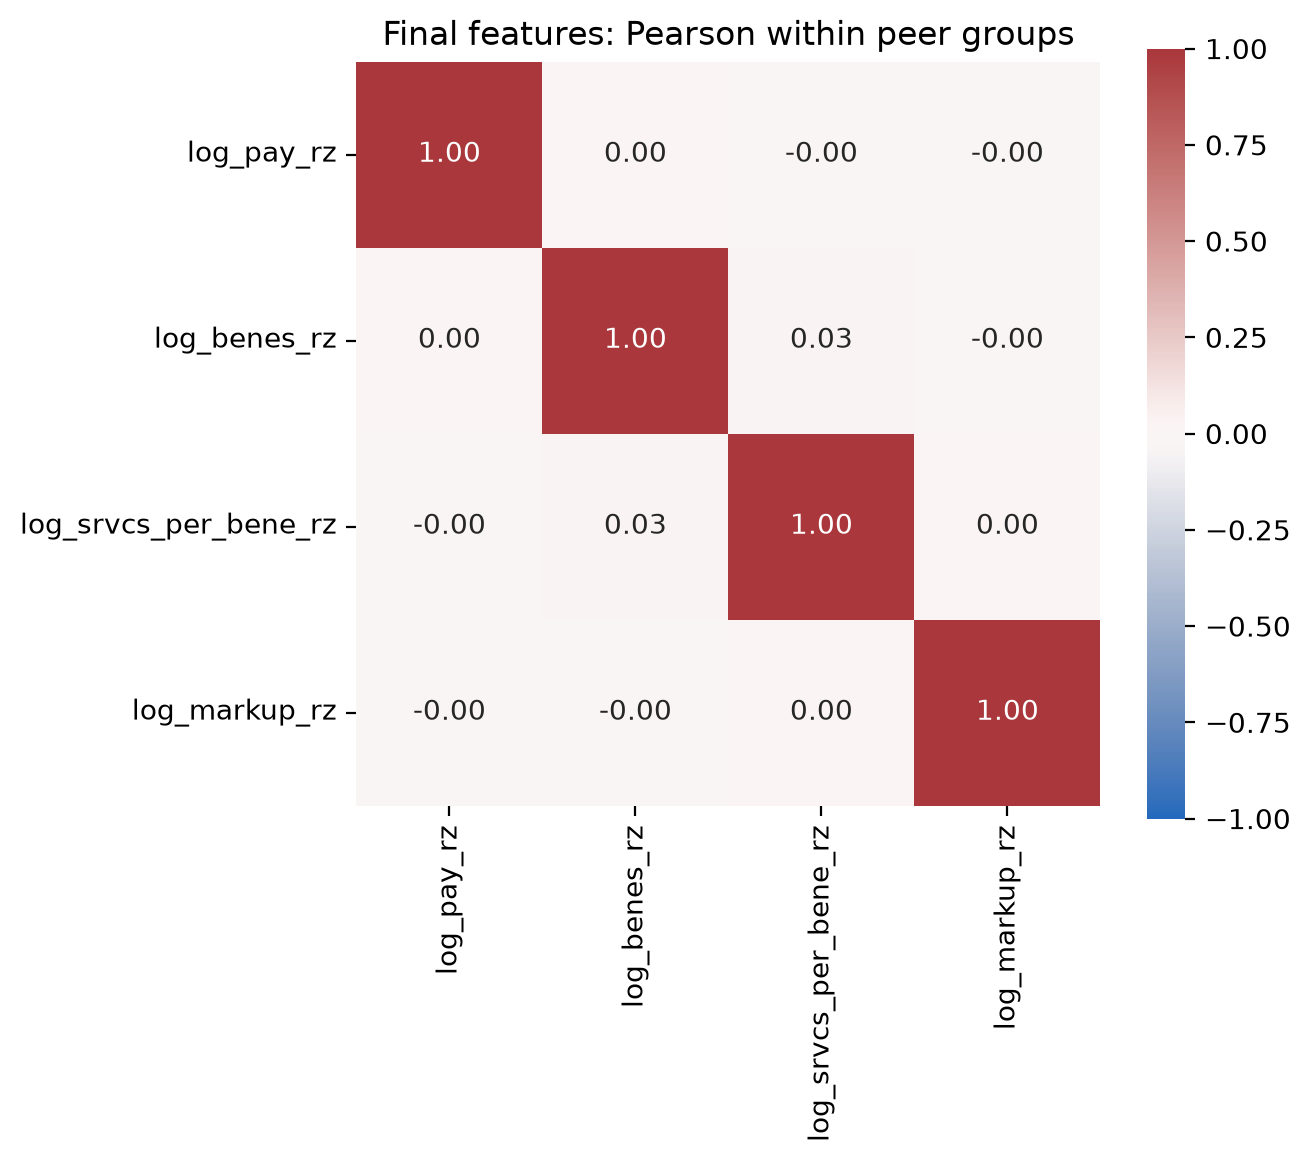

In [ ]:
_zr = peer_z.corr()
_fig, _ax = plt.subplots(figsize=(6, 5))
sns.heatmap(_zr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, ax=_ax)
_ax.set_title("Final features: Pearson within peer groups")
_fig
# pd.Series(np.diag(np.linalg.inv(_zr.values)), index=_zr.columns, name="VIF").round(2) # variance inflation factor check for confidence in what we select in this notebook, values closest to one mean all features are ideally dissimilar - the highest value is 1 leaving what we have is ok

# four features selected via testing: 'log_pay_rz': what medicare paid per service, 'log_benes_rz': how large the practice is, 'log_srvcs_per_bene_rz': how much billed per patient, 'log_markup_rz': how price is relative to medicare allowed amount
# we probably don't want more features if we can afford to not have them. it's noisy to repeatedly choose payments for splits in IsoForest, and counted multiple times in every distance of DBSCAN. 

Peer Grouping

In [ ]:
def robust_z(df, col, keys, min_n): # peer z-scores: grouping should be other providers billing the same service in same setting
    _by = [df[k] for k in keys]
    _g = df.groupby(keys, observed=True)[col]
    _med = _g.transform("median")
    _dev = (df[col] - _med).abs()
    _mad = _dev.groupby(_by, observed=True).transform("median")
    _meanad = _dev.groupby(_by, observed=True).transform("mean")
    _scale = (1.4826 * _mad).where(_mad > 0, 1.2533 * _meanad)
    _z = ((df[col] - _med) / _scale).where(_scale > 0, 0.0)
    return _z.where(_g.transform("size") >= min_n).astype("float32")

In [ ]:
_n = feats.groupby(["Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc"], observed=True)["Tot_Benes"].transform("size")
{k: round((_n < k).mean() * 100, 2) for k in [30, 50, 100, 200]}
# evaluated cost for peer grouping. this is the percent of rows that get scored against fallbacks, where the difference is 3.07% of rows move to HCPCS - POS fallback while still being scored.
# team has justified minimum peer group n=100 via bootstrap, where spread estimate decreases by nearly half for a small cost in data - can be backed with sensitivity check and top-k list comparison, and if rankings stablize around 100, the threshold will be properly backed

Model Matrix

In [ ]:
_ok = peer_z.notna().all(axis=1)
Z = peer_z[_ok].clip(lower=0) # one-sided: auditors don't really need to look at billing less than peers, and we don't want to flag low volume/intensity providers - rerun without clip to check sensitivity
Z.shape, _ok.mean() # confirms MAD fix worked, 1.07% of rows lacked greater than or equal to 100 peers and are reported as unscored rather than compared against an unreliable baseline

Baselines, z-score and percentile, and crosstab comparison

In [ ]:
base = pd.DataFrame({"base_score": Z.max(axis=1),
                     "base_reason": Z.idxmax(axis=1),
                     "n_over": (Z > 3.5).sum(axis=1)}, index=Z.index) # baseline, explainable benchmark that our models need to beat or agree with
base["base_flag"] = base["base_score"] > 3.5 # modified z-score cutoff to identify outliars using median and median absolute deviation - Boris Iglewicz, David C. Hoaglin 1993 Volume 16: How to Detect and Handle Outliers - note to self to add to citations if confirmed with team
base["base_flag"].mean(), base.loc[base.base_flag, "base_reason"].value_counts(normalize=True)

In [ ]:
def peer_pct(df, col, keys, min_n):
    _g = df.groupby(keys, observed=True)[col]
    return _g.rank(pct=True, method="average").where(_g.transform("size") >= min_n).astype("float32")

_lvl1 = ["Rndrng_Prvdr_Type", "HCPCS_Cd", "Place_Of_Srvc"]
_lvl2 = ["HCPCS_Cd", "Place_Of_Srvc"]
_pct = {}
for _c in ["log_pay", "log_benes", "log_srvcs_per_bene", "log_markup"]:
    _pct[f"{_c}_pct"] = peer_pct(feats, _c, _lvl1, 100).fillna(peer_pct(feats, _c, _lvl2, 100))
P = pd.DataFrame(_pct).loc[Z.index] # same rows as the z-score baseline

In [ ]:
_t = 0.99 ** 0.25 # ≈ 0.9975, so about 1% of rows are flagged overall
pct_base = pd.DataFrame({"pct_score": P.max(axis=1), "pct_reason": P.idxmax(axis=1)})
pct_base["pct_flag"] = pct_base["pct_score"] >= _t
pct_base["pct_flag"].mean(), pct_base.loc[pct_base.pct_flag, "pct_reason"].value_counts(normalize=True)

In [ ]:
# compare the two baselines
pd.crosstab(base["base_flag"], pct_base["pct_flag"], normalize="all").round(4) # rows flagged by both methods are the most robust

IsoForest

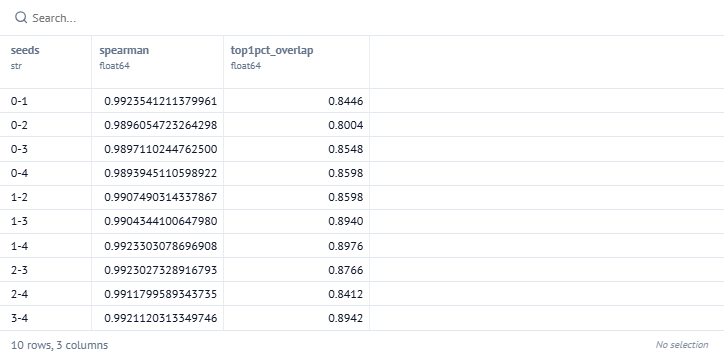

In [ ]:
from sklearn.ensemble import IsolationForest 
from scipy.stats import spearmanr
# 500k sample first
_S = Z.sample(500_000, random_state=1)
def iso(seed, X, fit_on=Z):
    _m = IsolationForest(n_estimators=200, max_samples=256, random_state=seed, n_jobs=-1).fit(fit_on)
    return pd.Series(-_m.score_samples(X), index=X.index)

def topk_overlap(a, b, q=0.01):
    _ta, _tb = a >= a.quantile(1 - q), b >= b.quantile(1 - q)
    return (_ta & _tb).sum() / _ta.sum()

_runs = [iso(s, _S) for s in range(5)]
pd.DataFrame([{"seeds": f"{i}-{j}", "spearman": spearmanr(_runs[i], _runs[j])[0],
               "top1pct_overlap": topk_overlap(_runs[i], _runs[j])}
              for i in range(5) for j in range(i + 1, 5)])

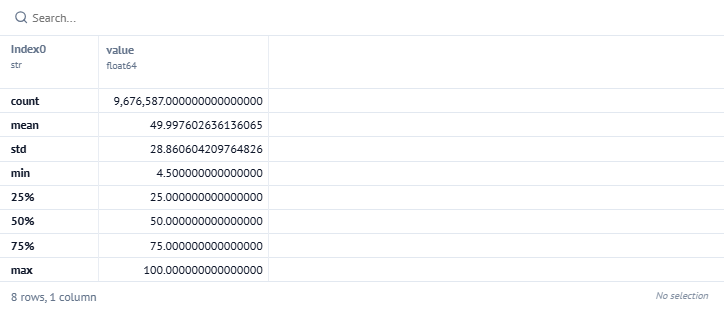

In [ ]:
# final scores?
with mo.persistent_cache(name="iso_scores"):
    _raw = IsolationForest(n_estimators=1000, max_samples=256, random_state=0, n_jobs=-1).fit(Z).score_samples(Z)
    iso_score = pd.Series(-_raw, index=Z.index)       # higher = more anomalous
risk_0_100 = (iso_score.rank(pct=True) * 100).round(1)
risk_0_100.describe()

DBSCAN

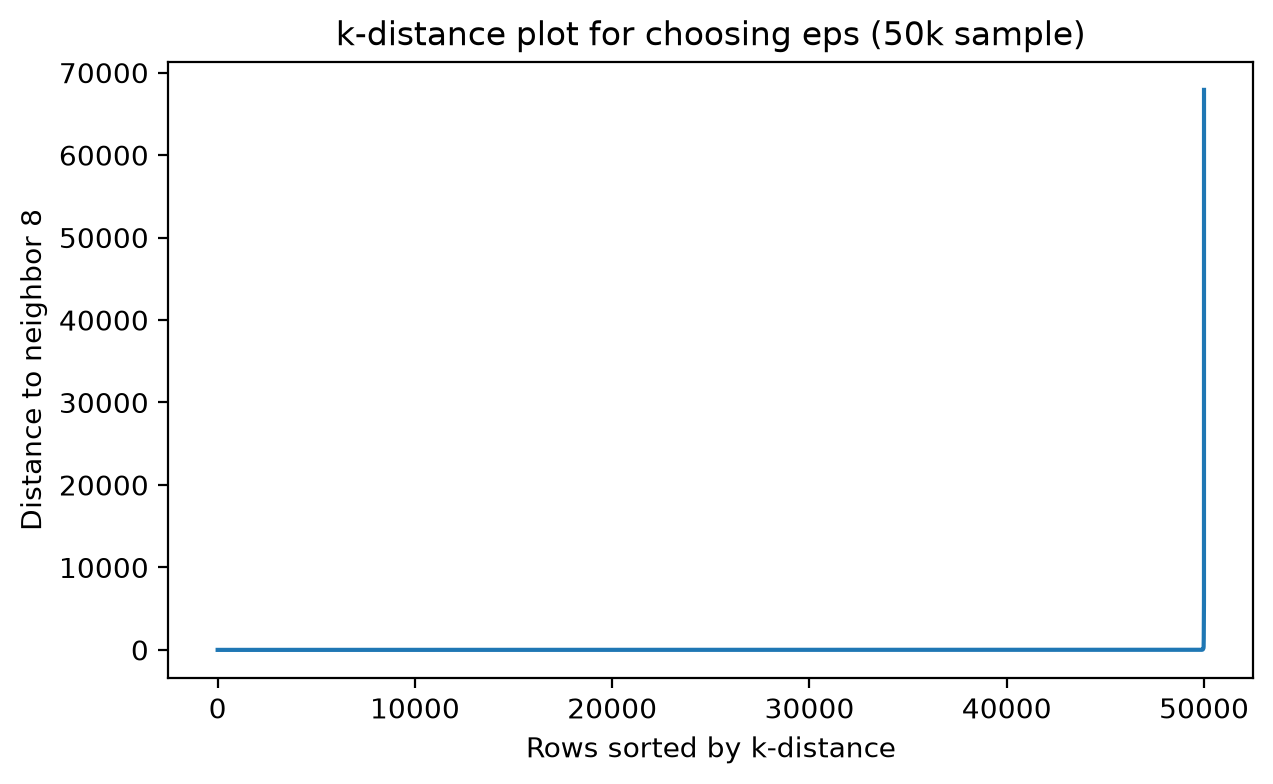

In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

D_sample = Z.sample(50_000, random_state=2) # DBSCAN memory grows roughly with n^2 in dense areas
k_nn = 8 # min_samples = 2 x number of features
_dist, _ = NearestNeighbors(n_neighbors=k_nn).fit(D_sample).kneighbors(D_sample)
kdist = pd.Series(_dist[:, -1], index=D_sample.index)

_fig, _ax = plt.subplots(figsize=(7, 4))
_ax.plot(np.sort(kdist.values))
_ax.set(xlabel="Rows sorted by k-distance", ylabel=f"Distance to neighbor {k_nn}",
        title="k-distance plot for choosing eps (50k sample)")
_fig

In [ ]:
eps = kdist.quantile(0.99)
_u, _inv, _cnt = np.unique(D_sample.to_numpy(), axis=0, return_inverse=True, return_counts=True)
_lab = DBSCAN(eps=eps, min_samples=k_nn, algorithm="ball_tree").fit_predict(_u, sample_weight=_cnt)
dbscan_noise = pd.Series(_lab[_inv.ravel()] == -1, index=D_sample.index)
{"eps": round(float(eps), 3), "unique points": len(_u), "noise share": dbscan_noise.mean()}

Comparisons

In [ ]:
_cmp = pd.DataFrame({"base": base.loc[D_sample.index, "base_score"],
                     "iso": iso_score.loc[D_sample.index], "kdist": kdist})
_iso_top = _cmp.iso >= _cmp.iso.quantile(0.99)
_cmp.corr(method="spearman").round(3), {
    "base vs iso (top 1%)": round(topk_overlap(_cmp.base, _cmp.iso), 3),
    "iso vs kdist (top 1%)": round(topk_overlap(_cmp.iso, _cmp.kdist), 3),
    "base vs kdist (top 1%)": round(topk_overlap(_cmp.base, _cmp.kdist), 3),
    "DBSCAN noise also in iso top 1%": round(_iso_top[dbscan_noise].mean(), 3)}